# CivicFlux — End-to-End Prediction and Decision Pipeline

## 01. Research workflow and decision boundaries

Demonstrate saved-artifact loading, supported predictions and bounded decision support without training models. The conceptual sequence is historical data → validation → causal features → supported research prediction → compatible infrastructure evidence → synthetic dependency analysis → transparent scoring → feasible allocation → human review → independent outcome verification.

Actual datasets have incompatible spatial identities. Delhi aggregate forecasts, unlocated traffic junctions and simulated L-TOWN sensors cannot be fused into one asset graph. The notebook shows those supported forecast lanes separately, then runs the complete decision sequence on a clearly identified synthetic graph with matching candidate assets. Weak success or onset scores never become operational facts.

### Setup and existing interfaces

Reuse the saved models, graph module, OR-Tools solver and verification helper. No alternate serving framework is introduced.

In [1]:
from pathlib import Path
import sys,json,platform,subprocess,copy
import numpy as np,pandas as pd,matplotlib.pyplot as plt,seaborn as sns
from IPython.display import display
ROOT=Path.cwd() if (Path.cwd()/'civicflux_core.py').exists() else Path.cwd().parent
sys.path.insert(0,str(ROOT))
from civicflux_core import sha256
from src.civicflux.serving import discover,directory_for,json_safe,SCOPES,UNITS,HORIZONS
from src.civicflux.validation import recompute_metrics,artifact_inventory,component_comparisons,registry_with_checks
sns.set_theme(style='whitegrid',palette='colorblind')
plt.rcParams.update({'figure.figsize':(11,4),'figure.dpi':110})
print('Python',platform.python_version(),'project',ROOT)

from src.civicflux.runtime import research_environment
from src.civicflux.serving import serve
from src.civicflux.integration import fixture,negative_requests,scenario_pipeline,review_proposal,compatible_graph_evidence
OUT=ROOT/'artifacts/end_to_end/v1.0.0';OUT.mkdir(parents=True,exist_ok=True)
CHECKS=ROOT/'reports/integration';CHECKS.mkdir(parents=True,exist_ok=True)

Python 3.13.5 project /Users/jiyahooda/Documents/New project/civicflux_ml


## 02. Discover exported models and research components

Only saved fitted artifacts can be checked for serving. Notebook-only candidate estimators without exports are not invented or recreated. The anomaly artifact includes multiple registered sensor suites; the fresh-process worker also checks every supported suite. Optimization has configuration/results instead of a fitted estimator and is validated as an algorithm.

### Inspect paths, input schemas and versions

Files are located using the same registry function as Notebook 10.

In [2]:
entries=discover(ROOT);display(pd.DataFrame(entries)[['component','component_kind','version','artifact','feature_schema','missing']])
for row in entries:
    if row['missing']:print('Missing requirements:',row['component'],row['missing'])

,component,component_kind,version,artifact,feature_schema,missing
0,rainfall,supervised time-series regression,legacy-unversioned,artifacts/rainfall/pipeline.joblib,artifacts/rainfall/feature_schema.json,[]
1,aqi,supervised time-series regression,legacy-unversioned,artifacts/aqi/pipeline.joblib,artifacts/aqi/feature_schema.json,[]
2,traffic,supervised time-series regression,legacy-unversioned,artifacts/traffic/pipeline.joblib,artifacts/traffic/feature_schema.json,[]
3,flood,supervised simulator,legacy-unversioned,artifacts/flood/pipeline.joblib,artifacts/flood/feature_schema.json,[]
4,infrastructure_anomaly,unsupervised detectors + data-quality rules,1.0.0,artifacts/infrastructure_anomaly/v1.0.0/detect...,artifacts/infrastructure_anomaly/v1.0.0/featur...,[]
5,water_network,supervised time-series regression,1.1.0,artifacts/water_network/v1.1.0/pipeline.joblib,artifacts/water_network/v1.1.0/feature_schema....,[]
6,cascade_risk,supervised simulator + graph rules,1.1.0,artifacts/cascade_risk/v1.1.0/pipeline.joblib,artifacts/cascade_risk/v1.1.0/feature_schema.json,[]
7,resource_optimization,CP-SAT optimization + greedy rules,1.1.0,None,artifacts/resource_optimization/v1.1.0/feature...,[]
8,intervention_outcomes,synthetic classification + duration regression,1.1.0,artifacts/intervention_outcomes/v1.1.0/pipelin...,artifacts/intervention_outcomes/v1.1.0/feature...,[]


## 03. Fresh Python process model-serving validation

Launch a separate ordinary Python process for each component. The worker imports reusable modules and existing bundles, not notebook variables or Jupyter. It predicts on genuinely supported held-out historical or synthetic inputs, tests incompatible requests, and fingerprints the artifact and serving interface.

On this macOS workspace XGBoost needs the OpenMP library path already used by the notebook executor. `research_environment()` supplies that launch environment from the installed scikit-learn distribution. This is a documented runtime requirement for a FastAPI process too; a failed load produces Not ready, never a fabricated prediction.

### Load, predict and challenge inputs outside Jupyter

The worker executes six or more negative cases per component. Runtime output and failures are retained in reports.

In [3]:
process_rows=[]
for entry in entries:
    component=entry['component'];destination=CHECKS/(component+'.json')
    command=[sys.executable,str(ROOT/'scripts/check_research_inference.py'),component,'--output',str(destination)]
    completed=subprocess.run(command,cwd=ROOT,env=research_environment(),capture_output=True,text=True,timeout=180)
    row={'component':component,'return_code':completed.returncode,'stdout':completed.stdout.strip(),'stderr':completed.stderr[-5000:]}
    if destination.exists():
        report=json.loads(destination.read_text());row.update(passed=report['passed'],jupyter_imported=report['jupyter_imported'],
          positive_status=report['positive']['status'],negative_cases=len(report['negative_cases']),registered_sensor_suites=len(report.get('sensor_results',{})))
    else:row.update(passed=False,jupyter_imported=None,positive_status='not_ready',negative_cases=0,registered_sensor_suites=0)
    process_rows.append(row)
process_checks=pd.DataFrame(process_rows);display(process_checks)
process_checks.to_csv(OUT/'fresh_process_checks.csv',index=False)
assert process_checks.passed.all(),'Inspect retained worker failures before declaring readiness'
assert not process_checks.jupyter_imported.any()

,component,return_code,stdout,stderr,passed,jupyter_imported,positive_status,negative_cases,registered_sensor_suites
0,rainfall,0,"{""component"": ""rainfall"", ""status"": ""supported...",,True,False,supported_research,8,0
1,aqi,0,"{""component"": ""aqi"", ""status"": ""supported_rese...",,True,False,supported_research,8,0
2,traffic,0,"{""component"": ""traffic"", ""status"": ""supported_...",,True,False,supported_research,8,0
3,flood,0,"{""component"": ""flood"", ""status"": ""supported_si...",,True,False,supported_simulation,7,0
4,infrastructure_anomaly,0,"{""component"": ""infrastructure_anomaly"", ""statu...",,True,False,supported_research,8,5
5,water_network,0,"{""component"": ""water_network"", ""status"": ""supp...",,True,False,supported_simulation,9,0
6,cascade_risk,0,"{""component"": ""cascade_risk"", ""status"": ""suppo...",,True,False,supported_simulation,9,0
7,resource_optimization,0,"{""component"": ""resource_optimization"", ""status...",,True,False,supported_simulation,9,0
8,intervention_outcomes,0,"{""component"": ""intervention_outcomes"", ""status...",,True,False,supported_simulation,9,0


### Inspect one actual response and registered detector coverage

The common envelope contains version, scope, provenance, validation limits, uncertainty if supported, and an explicit research status.

In [4]:
responses={r['component']:json.loads((CHECKS/(r['component']+'.json')).read_text()) for r in entries}
display(responses['rainfall']['positive'])
print('Registered sensor suites checked:',list(responses['infrastructure_anomaly'].get('sensor_results',{})))
print('No Jupyter modules imported in workers:',not process_checks.jupyter_imported.any())

{'contract_version': 'civicflux.research.v1',
 'component': 'rainfall',
 'model_version': 'legacy-unversioned',
 'status': 'supported_research',
 'prediction': [{'entity': 'Delhi',
   'time': '2021-02-27 00:00:00+05:30',
   'target_time': '2021-02-28 00:00:00+05:30',
   'prediction': 0.3234360962391534,
   'source_missing': 0}],
 'uncertainty': {'method': 'calibration-period pooled absolute residual radius; no conditional coverage guarantee',
  'level': 0.9,
  'intervals': [{'entity': 'Delhi',
    'lower_90': 0.0,
    'upper_90': 5.800203174431296}]},
 'provenance': 'reported real state aggregate; upstream lineage not independently audited',
 'validation_status': 'research; measurement lineage and reporting delays need validation',
 'geographic_scope': 'Delhi state aggregate',
 'units': 'mm/day',
 'horizon': 'next day',
 'research_only': True,
 'operational_supported': False,
 'allocation_eligible': False,
 'dispatch_allowed': False,
 'warnings': ['Research inference only; independent 

Registered sensor suites checked: ['rainfall:Delhi', 'aqi:Delhi', 'traffic:1', 'traffic:2', 'traffic:3']
No Jupyter modules imported in workers: True


## 04. Input validation and abstention behavior

The adapter validates scope, horizon and units before model loading; malformed payloads, missing observations, stale inputs and unsupported purposes abstain. Historical mode uses an explicit as-of clock and does not claim that an old observation is live. Unknown traffic timezones remain unknown source clocks. Synthetic experiments require synthetic provenance.

Water's operational fault output and intervention success probability are withheld. A technical simulation score remains available only within its documented research task.

### Audit negative request results

An explicit abstention contains a reason and no prediction. No exception is converted into a plausible number.

In [5]:
negative_rows=[]
for component,report in responses.items():
    for case,response in report['negative_cases'].items():
        negative_rows.append({'component':component,'case':case,'status':response['status'],'prediction_is_null':response['prediction'] is None,
          'reason':'; '.join(response['warnings'])[:500]})
negative_table=pd.DataFrame(negative_rows);display(negative_table)
negative_table.to_csv(OUT/'abstention_checks.csv',index=False)
assert negative_table.status.eq('abstained').all() and negative_table.prediction_is_null.all()
print('Water operational request:',responses['water_network']['negative_cases']['operational'])
print('Outcome research response:',responses['intervention_outcomes']['positive']['prediction'])

,component,case,status,prediction_is_null,reason
0,rainfall,wrong_units,abstained,True,Unit contract mismatch
1,rainfall,wrong_scope,abstained,True,Unsupported geographic/entity scope
2,rainfall,wrong_horizon,abstained,True,Horizon contract mismatch
3,rainfall,operational,abstained,True,Operational prediction/dispatch is unsupported
4,rainfall,stale,abstained,True,Stale inputs relative to explicit historical/s...
...,...,...,...,...,...
70,intervention_outcomes,stale,abstained,True,Stale inputs relative to explicit historical/s...
71,intervention_outcomes,missing_payload,abstained,True,'record'
72,intervention_outcomes,false_provenance,abstained,True,Explicit synthetic provenance is required
73,intervention_outcomes,unknown_intervention,abstained,True,Unknown intervention type


Water operational request: {'contract_version': 'civicflux.research.v1', 'component': 'water_network', 'model_version': '1.1.0', 'status': 'abstained', 'prediction': None, 'uncertainty': None, 'provenance': 'BattLeDIM CC BY 4.0 simulated SCADA', 'validation_status': 'weak temporal benchmark; operational abstention', 'geographic_scope': 'L-TOWN simulated network only', 'units': {'pressure': 'm', 'flow': 'm3/h', 'level': 'm'}, 'horizon': 'onset during preceding 24 hours', 'research_only': True, 'operational_supported': False, 'allocation_eligible': False, 'dispatch_allowed': False, 'warnings': ['Operational prediction/dispatch is unsupported']}
Outcome research response: {'research_resolution_hours': 17.75858186108582, 'success_probability': None, 'success_estimation_status': 'unsupported for decisions'}


## 05. Supported historical forecasts and uncertainty

Rainfall predicts the next Delhi state day; AQI predicts next-hour PM2.5 for the declared aggregate; traffic predicts next-hour vehicle counts for benchmark junction identities. The raw histories pass through the existing canonicalization, feature construction and fitted preprocessing. Intervals are pooled residual bands with no guarantee of conditional or live coverage.

### Show actual forecast outputs in separate domains

These are historical research inferences, not live readings. Axes retain their task units.

,component,entity,observation,target_time,prediction,lower_90,upper_90,units,scope
0,rainfall,Delhi,2021-02-27 00:00:00+05:30,2021-02-28 00:00:00+05:30,0.323436,0.000000,5.800203,mm/day,Delhi state aggregate
1,aqi,Delhi,2023-01-02 04:00:00+05:30,2023-01-02 05:00:00+05:30,66.473961,39.690317,93.257605,ug/m3 (working assumption; source unit metadat...,Delhi aggregate (station lineage unverified)
2,traffic,1,2017-03-02 18:00:00,2017-03-02 19:00:00,75.597443,70.028664,81.166222,vehicles/hour,unlocated benchmark junctions


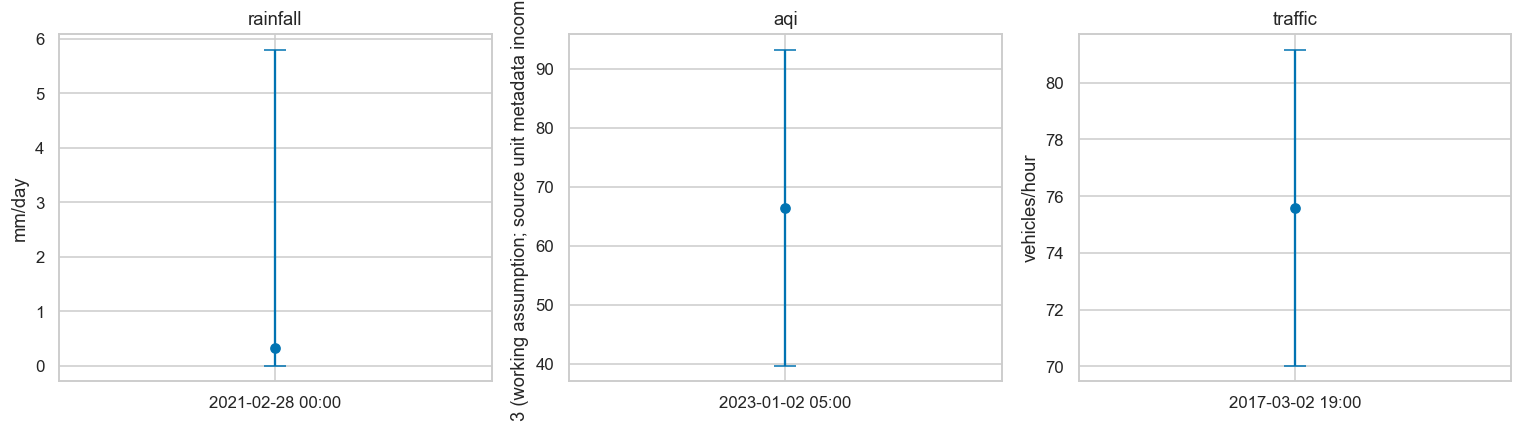

In [6]:
forecast_rows=[]
for component in ['rainfall','aqi','traffic']:
    response=responses[component]['positive'];record=response['prediction'][0]
    interval=response['uncertainty']['intervals'][0]
    forecast_rows.append({'component':component,'entity':record['entity'],'observation':record['time'],'target_time':record['target_time'],
     'prediction':record['prediction'],'lower_90':interval['lower_90'],'upper_90':interval['upper_90'],'units':response['units'],'scope':response['geographic_scope']})
forecasts=pd.DataFrame(forecast_rows);display(forecasts)
fig,axes=plt.subplots(1,3,figsize=(14,4))
for ax,row in zip(axes,forecasts.itertuples()):
    ax.errorbar([0],[row.prediction],yerr=[[row.prediction-row.lower_90],[row.upper_90-row.prediction]],fmt='o',capsize=7)
    ax.set(title=row.component,ylabel=row.units,xticks=[0],xticklabels=[row.target_time[:16]])
plt.tight_layout();plt.show();forecasts.to_csv(OUT/'historical_forecasts.csv',index=False)

## 06. Geographic, time and provenance compatibility

A common city string cannot map an aggregate to a specific pump. The shared graph evidence checker requires an existing node, synthetic status, matching graph identity and exact graph fingerprint. Forecast units and horizons are not silently converted to asset disruption probabilities. Cross-domain bridges without verified spatial/temporal mapping abstain.

### Demonstrate blocked and compatible evidence

The asset mapping check is exact for this seeded synthetic graph; it does not pretend to solve municipal geospatial matching.

In [7]:
from src.civicflux.graph import from_config,graph_fingerprint
cascade_request=fixture('cascade_risk',ROOT);graph=from_config(cascade_request['graph'])
evidence={'synthetic':True,'graph_id':graph.graph['graph_id'],'graph_fingerprint':graph_fingerprint(graph),'node_id':'pump_0'}
compatibility=pd.DataFrame([
 {'connection':'same declared synthetic graph/node','compatible':compatible_graph_evidence(evidence,graph)},
 {'connection':'same node name, wrong graph fingerprint','compatible':compatible_graph_evidence({**evidence,'graph_fingerprint':'unverified'},graph)},
 {'connection':'Delhi forecast to synthetic pump','compatible':compatible_graph_evidence({'synthetic':False,'node_id':'pump_0'},graph)}])
display(compatibility);compatibility.to_csv(OUT/'mapping_checks.csv',index=False)
assert compatibility.compatible.tolist()==[True,False,False]

,connection,compatible
0,same declared synthetic graph/node,True
1,"same node name, wrong graph fingerprint",False
2,Delhi forecast to synthetic pump,False


## 07. Synthetic infrastructure risk and cascade analysis

Declare a hypothetical initial pump disruption independently of weak forecasts. The selected Logistic Regression and NetworkX directed propagation operate on the existing synthetic dependency graph. The graph's IDs and fingerprint match Notebook 08's scenario assets. Node risk is scenario evidence, not a confirmed failure.

### Run the saved cascade bundle and visualize node scores

No retraining or graph replacement occurs. Colors show model scores on operational nodes; the initial disrupted node is excluded from the secondary-disruption target.

,node_id,risk,review
0,drainage_0,0.494207,True
19,water_3,0.417618,True
17,water_1,0.317580,True
6,drainage_6,0.257626,True
13,road_5,0.225306,True
10,road_2,0.179509,True
37,facility_6,0.154108,True
34,facility_3,0.137631,False
31,facility_0,0.126775,False
38,facility_7,0.125797,False


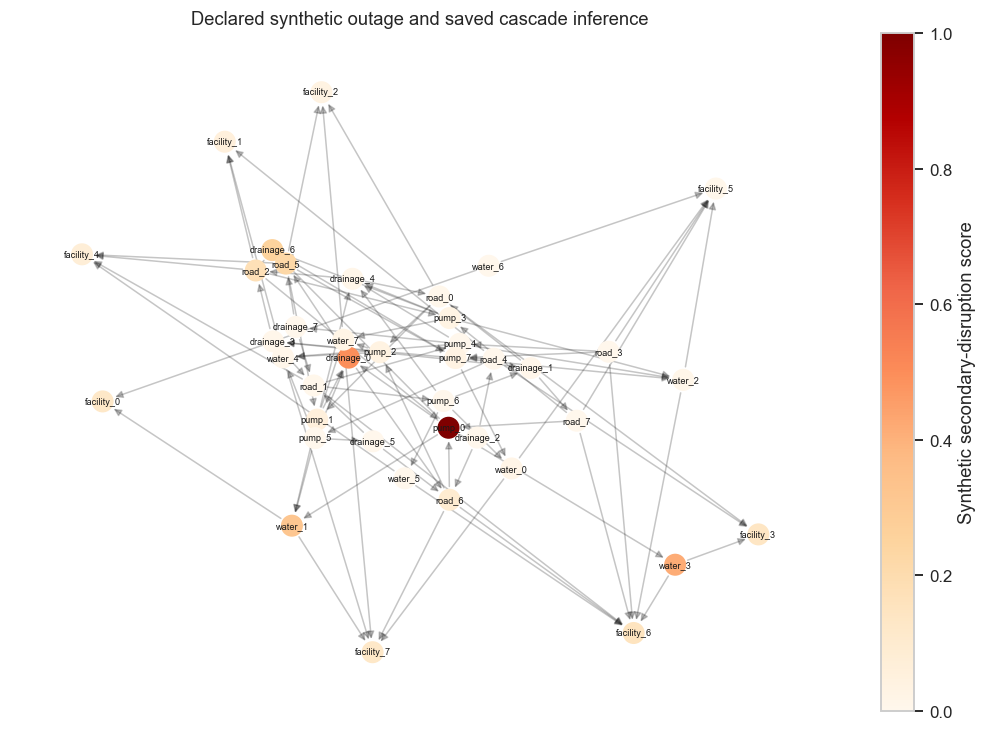

In [8]:
scenario=scenario_pipeline(ROOT)
assert scenario['status']=='supported_simulation'
node_risk=pd.DataFrame(scenario['cascade']['prediction']);display(node_risk.sort_values('risk',ascending=False).head(15))
import networkx as nx
pos=nx.spring_layout(graph,seed=42);risk_map=node_risk.set_index('node_id').risk.to_dict()
plt.figure(figsize=(12,8));nx.draw_networkx_edges(graph,pos,alpha=.25,arrows=True)
points=nx.draw_networkx_nodes(graph,pos,node_color=[risk_map.get(node,1.) for node in graph],cmap='OrRd',vmin=0,vmax=1,node_size=180)
nx.draw_networkx_labels(graph,pos,font_size=6);plt.colorbar(points,label='Synthetic secondary-disruption score');plt.title('Declared synthetic outage and saved cascade inference');plt.axis('off');plt.show()

### Explain a candidate dependency route

Trace uses directions, travel times and conditional edge transmission factors. It is a candidate exposure mechanism, not a realized path or causal claim.

In [9]:
from src.civicflux.cascade import dependency_trace,propagation_rule
node=node_risk.sort_values('risk',ascending=False).iloc[0].node_id
route=dependency_trace(graph,cascade_request['initial'],node,cascade_request['load'])
display(route)
reach=propagation_rule(graph,cascade_request['initial'])
print('NetworkX reachable operational nodes:',len(reach),'model review nodes:',int(node_risk.review.sum()))
(OUT/'cascade_route.json').write_text(json.dumps(json_safe(route),indent=2))

{'node_id': 'drainage_0',
 'horizon_minutes': 60,
 'paths': [{'initial_node': 'pump_0',
   'path': ['pump_0', 'drainage_0'],
   'arrival_minutes_if_transmitted': 10,
   'within_horizon': True,
   'single_path_transmission_product': 0.4068760848222874,
   'steps': [{'provider': 'pump_0',
     'dependent': 'drainage_0',
     'edge_weight': 0.607750746456588,
     'delay_minutes': 10,
     'target_resilience': 0.3913831418636287,
     'conditional_transmission': 0.4068760848222874}]}],
 'semantics': 'Candidate dependency routes; not realized failures or total cascade probability'}

NetworkX reachable operational nodes: 22 model review nodes: 7


711

## 08. Sustainability scoring and resource scarcity

Only compatible synthetic cascade scores enter hypothetical proposal factors. Urgency, service, costs, carbon and equity values retain their documented assumed provenance. Use the existing normalized scoring function and OR-Tools solver under shared budget/pump/crew limits. Success scores from Notebook 09 are explicitly rejected if supplied to allocation.

### Review normal and scarce allocations and constraints

Compare the same synthetic cases with a smaller budget. The solver result is a proposal with no dispatch authority.

,scenario,status,utility,selected,budget_used,budget_available,pumps_used,crew_hours_used,solver_seconds,dispatch_allowed
0,normal,OPTIMAL,9.030806,20,149988,150000,7,50.0,0.006044,False
1,scarce_budget,OPTIMAL,4.860787,10,51603,52500,2,22.0,0.001473,False


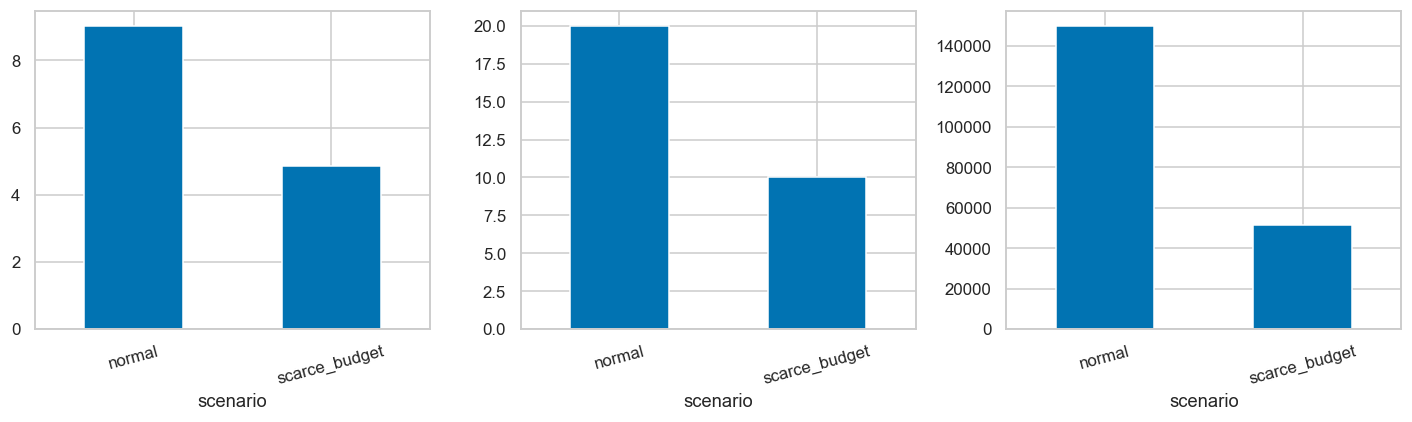

,case_id,node_id,urgency,cascade,environmental_benefit,equity_proxy,utility,cost,crew_type,duration_hours,pumps_required
0,S42-C01,drainage_1,0.8,9.938992e-03,0.926765,0.370798,0.481987,13695,drain,2.0,0
1,S42-C02,drainage_2,0.6,3.910425e-55,0.631664,0.827631,0.390563,3882,drain,1.0,0
2,S42-C03,drainage_3,1.0,9.832659e-03,0.466721,0.194639,0.515738,5005,drain,3.0,0
3,S42-C04,drainage_4,1.0,1.310767e-02,0.469556,0.370460,0.468024,11924,drain,3.0,1
4,S42-C05,drainage_5,0.6,5.456173e-55,0.832678,0.437152,0.455933,7060,drain,1.0,0
5,S42-C06,drainage_6,0.6,2.576256e-01,0.139752,0.682496,0.408116,13358,drain,4.0,1
6,S42-C07,drainage_7,0.8,2.775373e-04,0.458916,0.780729,0.513340,4817,drain,1.0,1
7,S42-C08,road_0,0.6,5.643920e-03,0.634718,0.764999,0.468193,13333,road,3.0,0
8,S42-C09,road_1,0.4,3.931192e-03,0.408529,0.214585,0.267091,6041,road,1.0,1
9,S42-C10,road_2,1.0,1.795093e-01,0.783898,0.557032,0.603113,8433,road,2.0,0


In [10]:
from src.civicflux.optimization import assert_feasible
allocation_rows=[]
for item in scenario['allocations']:
    response=item['allocation'];assert response['status']=='supported_simulation'
    allocation=response['prediction'];assert_feasible(allocation['selected'],allocation['available'])
    allocation_rows.append({'scenario':item['scenario'],'status':allocation['status'],'utility':allocation['objective'],'selected':len(allocation['selected']),
        'budget_used':allocation['used']['budget'],'budget_available':allocation['available']['budget'],'pumps_used':allocation['used']['pumps'],
        'crew_hours_used':sum(allocation['used']['crew_hours'].values()),'solver_seconds':allocation['solver_seconds'],'dispatch_allowed':allocation['dispatch_allowed']})
allocations=pd.DataFrame(allocation_rows);display(allocations)
fig,axes=plt.subplots(1,3,figsize=(13,4))
for ax,column in zip(axes,['utility','selected','budget_used']):allocations.plot.bar(x='scenario',y=column,ax=ax,rot=15,legend=False)
plt.tight_layout();plt.show();allocations.to_csv(OUT/'allocation_summary.csv',index=False)
normal=scenario['allocations'][0]['allocation']['prediction']
display(pd.DataFrame(normal['selected'])[['case_id','node_id','urgency','cascade','environmental_benefit','equity_proxy','utility','cost','crew_type','duration_hours','pumps_required']])

## 09. Human review and audit records

The existing optimizer requires human approval. No civic approval API or live dispatch system exists in this repository. A thin audit helper therefore records pending/deferred/rejected research proposals and cannot approve them. A fictional reviewer action below is visibly a synthetic walkthrough, not an actual human authorization.

Proposal, review, completion and outcome verification are distinct states. A high model score cannot approve work or confirm success.

### Inspect pending proposals and an explicitly fictional deferral

The research helper rejects approval and dispatch instructions.

In [11]:
review_records=[]
for item in scenario['allocations']:
    review_records += [item['review'],item['demonstration_review_record']]
display(pd.DataFrame(review_records))
try:review_proposal({'proposal_id':'SYNTHETIC-example'},decision='approve',reviewer='automated process')
except ValueError as error:print('Expected approval abstention:',error)
else:raise AssertionError('Research helper granted approval')
(OUT/'review_audit.json').write_text(json.dumps(review_records,indent=2))

,proposal_id,decision,reviewer,synthetic_demonstration,approval_status,dispatch_allowed,outcome_verified
0,SYNTHETIC-normal,pending,None,True,not_approved,False,False
1,SYNTHETIC-normal,defer,fictional reviewer in explicitly synthetic wal...,True,not_approved,False,False
2,SYNTHETIC-scarce_budget,pending,None,True,not_approved,False,False
3,SYNTHETIC-scarce_budget,defer,fictional reviewer in explicitly synthetic wal...,True,not_approved,False,False


Expected approval abstention: This research demonstration cannot approve or dispatch


1052

## 10. Outcome recording and independent verification

The outcome bundle can estimate research resolution time in its synthetic population, but exposes no operational success probability. Completed work is not verified success. Real outcome recording requires consistent timestamps, completion status, independent verifier and evidence. Synthetic rows cannot be promoted into real verified labels.

### Show completion and verification remain distinct

The existing verification helper refuses synthetic promotion. This is the expected end of the demonstration.

In [12]:
from src.civicflux.outcomes import validate_outcome_record,verify_outcome
records=pd.read_csv(directory_for(ROOT,'intervention_outcomes')/'synthetic_intervention_records.csv')
example=records[records.status.eq('completed')].iloc[0].to_dict()
validate_outcome_record(example)
display({'work_status':example['status'],'outcome_status':example['outcome_status'],'source_type':example['source_type']})
display(scenario['verification'])
assert scenario['verification']['status']=='abstained'
outcome_response=responses['intervention_outcomes']['positive'];assert outcome_response['prediction']['success_probability'] is None
print('Resolution estimate:',outcome_response['prediction']['research_resolution_hours'],'hours; synthetic completed-cohort research only')

{'work_status': 'completed',
 'outcome_status': 'verified_success',
 'source_type': 'synthetic'}

{'status': 'abstained',
 'reason': 'Simulation outcomes cannot be promoted to real verified outcomes',
 'completed_work_is_verified_success': False}

Resolution estimate: 17.75858186108582 hours; synthetic completed-cohort research only


## 11. Integration tests and honest readiness classifications

Technical readiness is assigned only after fresh-process loading, compatible prediction and incompatible-input tests pass. Synthetic models remain Simulation/demo only even if technically functional. Weak water and outcome success predictions remain operationally unsupported. Research forecasts retain their geographic and source-quality restrictions.

### Build the final evidence-based registry

Readiness checks also require matching artifact and serving-interface hashes, preventing stale reports from certifying changed files.

,component,readiness,readiness_reason,operational_supported
0,rainfall,Backend-ready for research inference,"Fresh Python process loaded artifact, predicte...",False
1,aqi,Backend-ready for research inference,"Fresh Python process loaded artifact, predicte...",False
2,traffic,Backend-ready for research inference,"Fresh Python process loaded artifact, predicte...",False
3,flood,Simulation/demo only,"Fresh Python process loaded artifact, predicte...",False
4,infrastructure_anomaly,Backend-ready for research inference,"Fresh Python process loaded artifact, predicte...",False
5,water_network,Simulation/demo only,"Fresh Python process loaded artifact, predicte...",False
6,cascade_risk,Simulation/demo only,"Fresh Python process loaded artifact, predicte...",False
7,resource_optimization,Simulation/demo only,"Fresh Python process loaded artifact, predicte...",False
8,intervention_outcomes,Simulation/demo only,"Fresh Python process loaded artifact, predicte...",False


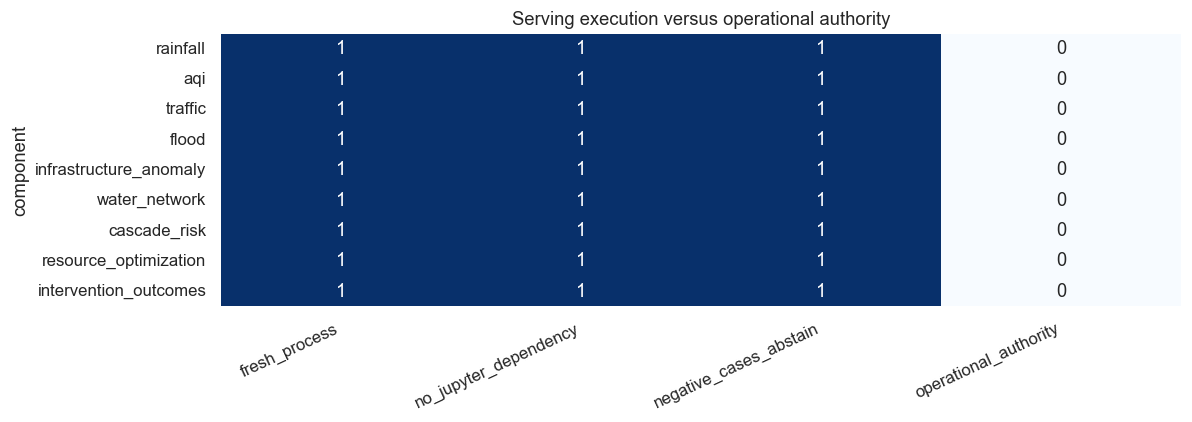

In [13]:
registry=registry_with_checks(ROOT,CHECKS);readiness=pd.DataFrame(registry)
display(readiness[['component','readiness','readiness_reason','operational_supported']])
assert readiness.readiness.ne('Not ready').all(),'Some components require further loading/inference repair'
assert not readiness.operational_supported.any()
checks=pd.DataFrame({'component':process_checks.component,'fresh_process':process_checks.passed,'no_jupyter_dependency':~process_checks.jupyter_imported,
                    'negative_cases_abstain':process_checks.passed,'operational_authority':False})
sns.heatmap(checks.set_index('component').astype(int),annot=True,cbar=False,cmap='Blues',vmin=0,vmax=1);plt.title('Serving execution versus operational authority');plt.xticks(rotation=25,ha='right');plt.tight_layout();plt.show()

### Run the changed-behavior and integration tests

The suite checks causal features, threshold coverage, outcome suppression, provenance, constraints, serialization and metric consistency.

In [14]:
result=subprocess.run([sys.executable,'-m','pytest','-q','tests'],cwd=ROOT,env=research_environment(),capture_output=True,text=True,timeout=180)
print(result.stdout);print(result.stderr)
(OUT/'tests.txt').write_text(result.stdout+'\n'+result.stderr)
assert result.returncode==0,'Inspect the test report before claiming completion'

.....................................................                    [100%]
53 passed in 2.16s




## 12. Export API-compatible research evidence

Export the common registry, example responses, scenario allocations, audit trace and fresh-process summaries. A FastAPI route can call `src.civicflux.serving.serve(component, request, project_root)` directly. It returns JSON-compatible values and explicit abstentions; no web server is created here.

On macOS launch the serving process with `research_environment()` or an equivalent configured OpenMP path. Authenticating a real operator and implementing a real approval API remain application work; this research notebook has no authority to provide those decisions.

### Save registry, responses and reproducible scenario reports

The new artifacts contain predictions and decisions already executed in this notebook, not assumed backend responses.

In [15]:
exports={'model_registry.json':registry,'example_api_responses.json':{k:v['positive'] for k,v in responses.items()},'scenario_results.json':scenario,
         'audit_trace.json':scenario['audit_trace'],'metadata.json':{'component':'end_to_end_research_validation','version':'1.0.0','retrained_models':0,
             'fresh_process_components':len(registry),'operational_dispatch':False,'limitations':['no verified common municipal mapping','synthetic decisions and outcomes','weak fault/success policies abstain operationally','runtime OpenMP launch requirement']}}
for filename,payload in exports.items():(OUT/filename).write_text(json.dumps(json_safe(payload),indent=2,allow_nan=False))
print('Exports:',OUT)

Exports: /Users/jiyahooda/Documents/New project/civicflux_ml/artifacts/end_to_end/v1.0.0


## 13. Actual completion report and remaining limitations

All supported paths must be read in their research context. Passing tests proves that the interfaces load and execute for supported fixtures, not that their measurements, probabilities or decisions are valid in a live city. The complete decision trace therefore uses declared synthetic incidents, aligned synthetic graph nodes and hypothetical resources. It ends at pending human review and refuses promotion of simulated outcomes to real verified success.

Remaining evidence includes measured local incidents, verified sensor clocks/units, geospatial asset mappings, actual inventories and independently audited outcomes. No additional estimator is trained merely to label these final evaluation notebooks as models.

### Final per-component status

The table below is populated by actual fresh-process reports from this execution.

In [16]:
display(readiness[['component','readiness','geographic_scope','validation_status']])
print('Fresh processes:',int(process_checks.passed.sum()),'negative requests:',int(process_checks.negative_cases.sum()),
      'registered anomaly suites:',int(process_checks.registered_sensor_suites.sum()))
print('Automatic dispatch:',scenario['automatic_dispatch'],'cross-scope bridge:',scenario['blocked_cross_scope_bridge']['status'])

,component,readiness,geographic_scope,validation_status
0,rainfall,Backend-ready for research inference,Delhi state aggregate,research; measurement lineage and reporting de...
1,aqi,Backend-ready for research inference,Delhi aggregate (station lineage unverified),research; measurement lineage and reporting de...
2,traffic,Backend-ready for research inference,unlocated benchmark junctions,research; measurement lineage and reporting de...
3,flood,Simulation/demo only,hypothetical catchments with state-rainfall re...,research scenario surrogate; not validated rea...
4,infrastructure_anomaly,Backend-ready for research inference,source-specific unmapped benchmark sensors,research evidence only
5,water_network,Simulation/demo only,L-TOWN simulated network only,weak temporal benchmark; operational abstention
6,cascade_risk,Simulation/demo only,synthetic civic dependency graphs,unseen synthetic graph holdout; no municipal v...
7,resource_optimization,Simulation/demo only,synthetic intervention scenarios,scenario feasibility verified; no real resourc...
8,intervention_outcomes,Simulation/demo only,synthetic intervention records only,chronological synthetic holdout; unsupported s...


Fresh processes: 9 negative requests: 75 registered anomaly suites: 5
Automatic dispatch: False cross-scope bridge: abstained
